Celda 1: importaciones

In [1]:
import ast
import hashlib

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from fraude_recibos import config

FINDIT_DIR = config.FINDIT_DIR
SPLITS = ["train", "val", "test"]

Celda 2: funciones de lectura

In [2]:
def parsear_anotacion(valor):
    """Convierte el texto de la anotación en diccionario.

    Las anotaciones usan formato de diccionario de Python (comillas simples,
    True con mayúscula), por eso se usa ast.literal_eval y no json.loads.
    Los recibos auténticos tienen el valor '0'.
    """
    if pd.isna(valor) or str(valor).strip() in ("", "0"):
        return None
    return ast.literal_eval(valor)


def cargar_metadata():
    partes = []
    for split in SPLITS:
        df = pd.read_csv(FINDIT_DIR / f"{split}.txt", dtype={"forgery annotations": str})
        df["split"] = split
        partes.append(df)

    df = pd.concat(partes, ignore_index=True)
    df.columns = df.columns.str.strip().str.replace(" ", "_")

    df["id"] = df["image"].str.removesuffix(".png")
    df["ruta_imagen"] = df["split"] + "/" + df["image"]
    df["ruta_texto"] = df["split"] + "/" + df["id"] + ".txt"
    df["anotacion"] = df["forgery_annotations"].map(parsear_anotacion)
    return df


df = cargar_metadata()
df.head()

,image,digital_annotation,handwritten_annotation,forged,forgery_annotations,split,id,ruta_imagen,ruta_texto,anotacion
0,X00016469622.png,1,1,1,"{'filename': 'X00016469622.png', 'size': 23072...",train,X00016469622,train/X00016469622.png,train/X00016469622.txt,"{'filename': 'X00016469622.png', 'size': 23072..."
1,X00016469623.png,1,1,0,0,train,X00016469623,train/X00016469623.png,train/X00016469623.txt,None
2,X00016469670.png,1,1,0,0,train,X00016469670,train/X00016469670.png,train/X00016469670.txt,None
3,X00016469671.png,1,1,0,0,train,X00016469671,train/X00016469671.png,train/X00016469671.txt,None
4,X00016469672.png,1,1,0,0,train,X00016469672,train/X00016469672.png,train/X00016469672.txt,None


Celda 3: tabla de regiones falsificadas

In [3]:
sin_anotacion = df[(df["forged"] == 1) & (df["anotacion"].isna())]
print("Falsificados sin anotación:", len(sin_anotacion))
sin_anotacion[["id", "split", "forgery_annotations"]]

Falsificados sin anotación: 1


,id,split,forgery_annotations
544,X51008114260,train,0


In [4]:
def leer_tecnicas(valor):
    """Normaliza 'Modified area', que viene en distintos formatos según el recibo."""
    if isinstance(valor, dict):
        return [k for k, v in valor.items() if v]
    if isinstance(valor, str):
        return [valor] if valor.strip() else []
    if isinstance(valor, (list, tuple)):
        return [str(v) for v in valor]
    return []


def extraer_regiones(df):
    filas = []
    falsificados = df[(df["forged"] == 1) & (df["anotacion"].notna())]
    for _, recibo in falsificados.iterrows():
        anotacion = recibo["anotacion"]
        software = anotacion.get("file_attributes", {}).get("Software used")
        for region in anotacion.get("regions", []):
            forma = region["shape_attributes"]
            atributos = region["region_attributes"]
            filas.append({
                "id": recibo["id"],
                "split": recibo["split"],
                "forma": forma.get("name"),
                "x": forma.get("x"),
                "y": forma.get("y"),
                "ancho": forma.get("width"),
                "alto": forma.get("height"),
                "tecnica": ",".join(leer_tecnicas(atributos.get("Modified area"))),
                "tipo_modified_area": type(atributos.get("Modified area")).__name__,
                "entidad": atributos.get("Entity type"),
                "area_original": atributos.get("Original area") == "yes",
                "software": software,
            })
    return pd.DataFrame(filas)


regiones = extraer_regiones(df)
print(regiones["forma"].value_counts(), "\n")
print(regiones["tipo_modified_area"].value_counts(), "\n")
print(regiones["tecnica"].value_counts())

forma
rect    664
Name: count, dtype: int64 

tipo_modified_area
dict    662
str       2
Name: count, dtype: int64 

tecnica
CPI              337
None             197
CUT               36
IMI               35
PIX               27
CPO                8
CUT,CPI            6
CPI,PIX            6
CPI,Autre          5
CPI,CUT            1
CPO,CUT,Autre      1
Autre              1
PIX,CPO            1
CPI,IMI            1
CPI,Autre,CUT      1
CUT,PIX            1
Name: count, dtype: int64


In [5]:
pd.crosstab(regiones["tecnica"] == "None", regiones["area_original"])

area_original,False,True
tecnica,,
False,464,3
True,1,196


Celda 4: controles de calidad

In [6]:
repetidos = df[df["id"].duplicated(keep=False)]
repetidos[["id", "split", "forged", "digital_annotation", "handwritten_annotation"]]

,id,split,forged,digital_annotation,handwritten_annotation
575,X51006619709,train,0,0,0
693,X51006619709,val,1,0,0


In [7]:
for split in SPLITS:
    ruta = FINDIT_DIR / split / "X51006619709.png"
    print(split, ruta.exists())

train True
val False
test False


In [8]:
# 1. Cada recibo tiene su imagen y su transcripción
df["existe_imagen"] = df["ruta_imagen"].map(lambda r: (FINDIT_DIR / r).exists())
df["existe_texto"] = df["ruta_texto"].map(lambda r: (FINDIT_DIR / r).exists())
print("Imágenes faltantes:", (~df["existe_imagen"]).sum())
print("Transcripciones faltantes:", (~df["existe_texto"]).sum())

# 2. Archivos en carpetas que no están en las etiquetas
for split in SPLITS:
    en_carpeta = {p.name for p in (FINDIT_DIR / split).glob("*.png")}
    en_etiquetas = set(df.loc[df["split"] == split, "image"])
    print(f"{split}: {len(en_carpeta - en_etiquetas)} imágenes sin etiqueta")

# 3. Ningún recibo en dos particiones (por nombre)
print("IDs repetidos:", df["id"].duplicated().sum())


# 4. Ningún recibo en dos particiones (por contenido de la imagen)
def hash_archivo(ruta):
    return hashlib.md5((FINDIT_DIR / ruta).read_bytes()).hexdigest()


df["hash"] = None
df.loc[df["existe_imagen"], "hash"] = df.loc[df["existe_imagen"], "ruta_imagen"].map(hash_archivo)

con_hash = df[df["existe_imagen"]]
duplicados = con_hash[con_hash["hash"].duplicated(keep=False)].sort_values("hash")
print("Imágenes idénticas con distinto nombre:", len(duplicados))
duplicados[["id", "split", "forged"]]

Imágenes faltantes: 1
Transcripciones faltantes: 1
train: 0 imágenes sin etiqueta
val: 0 imágenes sin etiqueta
test: 0 imágenes sin etiqueta
IDs repetidos: 1
Imágenes idénticas con distinto nombre: 2


,id,split,forged
16,X51005301661,train,0
19,X51005303661,train,0


In [9]:
# Recibo con etiquetas contradictorias entre particiones (auténtico en train,
# falsificado en val) y una sola imagen: se excluye por completo.
ids_excluidos = ["X51006619709"]

filas_excluidas = df[df["id"].isin(ids_excluidos) | ~df["existe_imagen"] | ~df["existe_texto"]]
print("Filas eliminadas:")
print(filas_excluidas[["id", "split", "forged"]])

df = df[~df.index.isin(filas_excluidas.index)].reset_index(drop=True)
regiones = regiones[~regiones["id"].isin(ids_excluidos)].reset_index(drop=True)

print("\nRecibos restantes:", len(df))
print("IDs repetidos:", df["id"].duplicated().sum())
print("Imágenes faltantes:", (~df["existe_imagen"]).sum())

# Imágenes idénticas con distinto nombre: se conserva la primera aparición.
duplicados_hash = df[df["hash"].duplicated(keep="first")]
print("\nDuplicados por contenido eliminados:")
print(duplicados_hash[["id", "split", "forged"]])

df = df.drop_duplicates(subset="hash", keep="first").reset_index(drop=True)
regiones = regiones[regiones["id"].isin(df["id"])].reset_index(drop=True)

print("\nRecibos finales:", len(df))

Filas eliminadas:
               id  split  forged
575  X51006619709  train       0
693  X51006619709    val       1

Recibos restantes: 986
IDs repetidos: 0
Imágenes faltantes: 0

Duplicados por contenido eliminados:
              id  split  forged
19  X51005303661  train       0

Recibos finales: 985


Celda 5: balance de clases por partición

In [10]:
resumen = df.groupby("split").agg(
    recibos=("id", "count"),
    falsificados=("forged", "sum"),
)
resumen["pct_fraude"] = (resumen["falsificados"] / resumen["recibos"] * 100).round(1)
resumen.loc[SPLITS]

,recibos,falsificados,pct_fraude
split,,,
train,575,94,16.3
val,192,33,17.2
test,218,35,16.1


Celda 6: características de las imágenes

In [11]:
def propiedades_imagen(ruta):
    with Image.open(FINDIT_DIR / ruta) as img:
        ancho, alto = img.size
        modo = img.mode
    peso_kb = (FINDIT_DIR / ruta).stat().st_size / 1024
    return pd.Series({"ancho_px": ancho, "alto_px": alto, "modo": modo, "peso_kb": peso_kb})


df = df.join(df["ruta_imagen"].apply(propiedades_imagen))

train = df[df["split"] == "train"]
print(train["modo"].value_counts())
train[["ancho_px", "alto_px", "peso_kb"]].describe().round(0)

modo
L       329
RGB     190
RGBA     48
LA        8
Name: count, dtype: int64


,ancho_px,alto_px,peso_kb
count,575.0,575.0,575.0
mean,1415.0,2474.0,1127.0
std,1490.0,1936.0,3987.0
min,435.0,768.0,32.0
25%,700.0,1430.0,323.0
50%,880.0,1713.0,568.0
75%,936.0,2213.0,1002.0
max,4961.0,7016.0,68105.0


In [12]:
## Revisión de atajos

In [13]:
print("Modo de color vs. falsificación (entrenamiento):")
print(pd.crosstab(train["modo"], train["forged"], margins=True), "\n")

print("% de falsificados por modo:")
print((pd.crosstab(train["modo"], train["forged"], normalize="index")[1] * 100).round(1), "\n")

print("Tamaño de las imágenes según la etiqueta:")
train.groupby("forged")[["ancho_px", "alto_px", "peso_kb"]].median().round(0)

Modo de color vs. falsificación (entrenamiento):
forged    0   1  All
modo                
L       302  27  329
LA        0   8    8
RGB     179  11  190
RGBA      0  48   48
All     481  94  575 

% de falsificados por modo:
modo
L         8.2
LA      100.0
RGB       5.8
RGBA    100.0
Name: 1, dtype: float64 

Tamaño de las imágenes según la etiqueta:


,ancho_px,alto_px,peso_kb
forged,,,
0,831.0,1699.0,489.0
1,888.0,1770.0,1154.0


In [14]:
## Anatomía de los fraudes

In [15]:
import numpy as np


def cargar_canonica(ruta):
    """Representación única para todo el proyecto: escala de grises, sin alfa."""
    with Image.open(FINDIT_DIR / ruta) as img:
        if img.mode in ("RGBA", "LA"):
            fondo = Image.new("RGBA", img.size, (255, 255, 255, 255))
            img = Image.alpha_composite(fondo, img.convert("RGBA"))
        return np.array(img.convert("L"))


def alfa_opaco(ruta):
    with Image.open(FINDIT_DIR / ruta) as img:
        return np.array(img.getchannel("A")).min() == 255


# ¿El canal alfa contiene información o es completamente opaco?
con_alfa = train[train["modo"].isin(["RGBA", "LA"])]
opacos = con_alfa["ruta_imagen"].map(alfa_opaco)
print(f"Imágenes con alfa totalmente opaco: {opacos.sum()} de {len(opacos)}")

# La conversión deja todas las imágenes en el mismo formato
ejemplo = cargar_canonica(con_alfa["ruta_imagen"].iloc[0])
print("Forma:", ejemplo.shape, "| Tipo:", ejemplo.dtype)

Imágenes con alfa totalmente opaco: 56 de 56
Forma: (933, 461) | Tipo: uint8


Verificación de las regiones None

In [16]:
pd.crosstab(regiones["tecnica"] == "None", regiones["area_original"])

area_original,False,True
tecnica,,
False,463,3
True,1,196


Celda 7: anatomía de los fraudes (solo entrenamiento)

In [17]:
# Zona alterada: no es zona de origen de una copia y tiene técnica registrada.
regiones["alterada"] = (~regiones["area_original"]) & (regiones["tecnica"] != "None")
reg_train = regiones[(regiones["split"] == "train") & regiones["alterada"]].copy()

print("Entidades modificadas:")
print(reg_train["entidad"].value_counts(), "\n")
print("Técnicas:")
print(reg_train["tecnica"].value_counts(), "\n")
print("Software:")
print(reg_train.drop_duplicates("id")["software"].value_counts(), "\n")
print("Regiones modificadas por recibo:")
print(reg_train.groupby("id").size().describe().round(1))

# Tamaño de la zona alterada en relación con el recibo
reg_train = reg_train.merge(df[["id", "ancho_px", "alto_px"]], on="id")
reg_train["pct_area"] = (
    reg_train["ancho"] * reg_train["alto"] / (reg_train["ancho_px"] * reg_train["alto_px"]) * 100
)
print("\n% del recibo que ocupa cada zona alterada:")
print(reg_train["pct_area"].describe().round(3))

Entidades modificadas:
entidad
Total/payment    151
Product           52
Metadata          46
Other             13
Company           10
Name: count, dtype: int64 

Técnicas:
tecnica
CPI              186
CUT               23
PIX               20
IMI               19
CPI,PIX            6
CPI,Autre          5
CUT,CPI            4
CPO                4
CPI,CUT            1
CPO,CUT,Autre      1
Autre              1
PIX,CPO            1
CPI,IMI            1
Name: count, dtype: int64 

Software:
software
gimp           40
paint          38
paint3d         7
aperçu          7
kolourpaint     1
Name: count, dtype: int64 

Regiones modificadas por recibo:
count    93.0
mean      2.9
std       2.6
min       1.0
25%       1.0
50%       2.0
75%       4.0
max      15.0
dtype: float64

% del recibo que ocupa cada zona alterada:
count    272.000
mean       0.396
std        3.084
min        0.004
25%        0.026
50%        0.043
75%        0.080
max       41.593
Name: pct_area, dtype: float64


Celda 8: recibos auténticos con anotaciones

In [18]:
pd.crosstab(
    [train["digital_annotation"], train["handwritten_annotation"]],
    train["forged"],
    margins=True,
)

forged                                       0   1  All
digital_annotation handwritten_annotation              
0                  0                       210  47  257
                   1                       239  45  284
1                  0                        12   1   13
                   1                        20   1   21
All                                        481  94  575

Celda 9: visualización

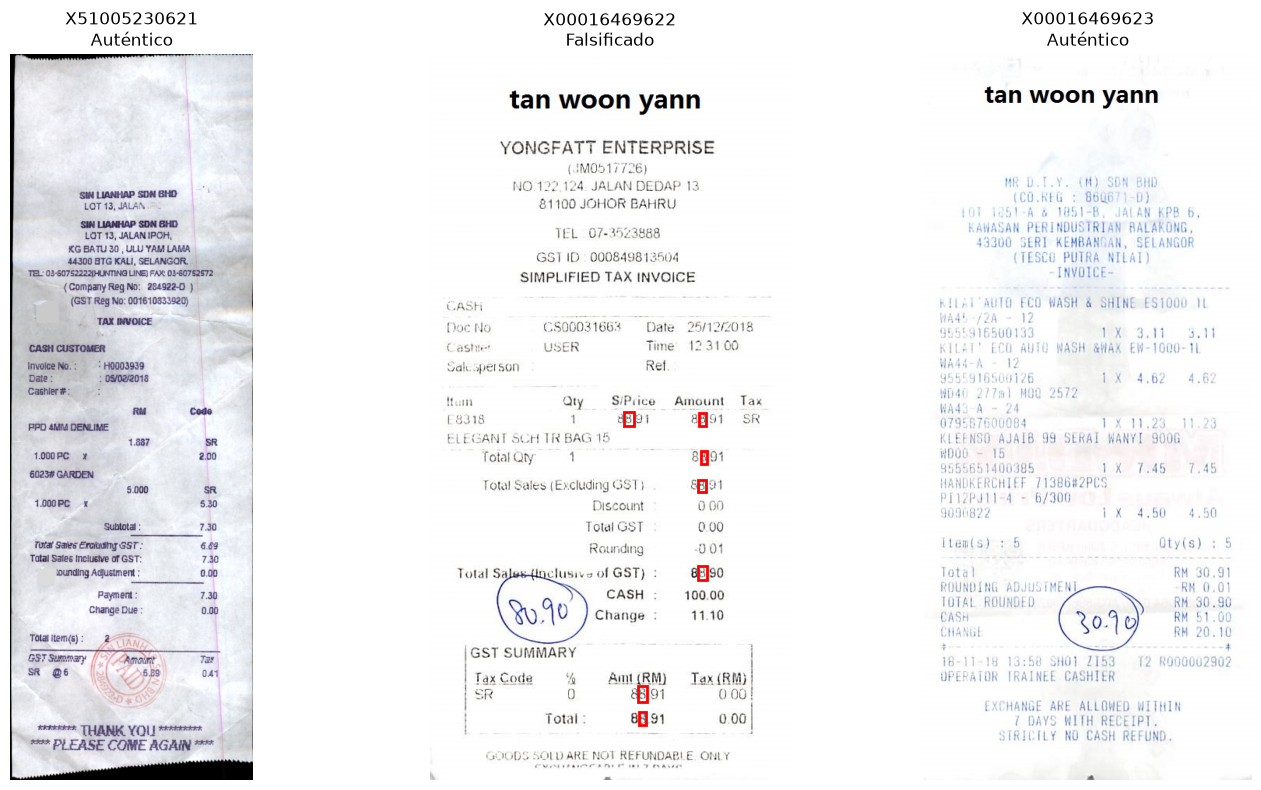

In [19]:
def mostrar_recibo(id_recibo, ax):
    recibo = df[df["id"] == id_recibo].iloc[0]
    with Image.open(FINDIT_DIR / recibo["ruta_imagen"]) as img:
        ax.imshow(img, cmap="gray")
    for _, r in regiones[(regiones["id"] == id_recibo) & regiones["alterada"]].iterrows():
        ax.add_patch(patches.Rectangle(
            (r["x"], r["y"]), r["ancho"], r["alto"],
            linewidth=2, edgecolor="red", facecolor="none",
        ))
    estado = "Falsificado" if recibo["forged"] else "Auténtico"
    ax.set_title(f"{id_recibo}\n{estado}")
    ax.axis("off")


ejemplos = [
    train[(train["forged"] == 0) & (train["handwritten_annotation"] == 0)]["id"].iloc[0],
    train[train["forged"] == 1]["id"].iloc[0],
    train[(train["forged"] == 0) & (train["handwritten_annotation"] == 1)]["id"].iloc[0],
]

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for id_recibo, ax in zip(ejemplos, axes):
    mostrar_recibo(id_recibo, ax)
plt.tight_layout()
fig.savefig(config.REPORTS_DIR / "ejemplos_recibos.png", dpi=120, bbox_inches="tight")
plt.show()

Celda 10: guardar las tablas

In [20]:
columnas = [
    "id", "split", "ruta_imagen", "ruta_texto", "forged",
    "digital_annotation", "handwritten_annotation",
    "ancho_px", "alto_px", "modo", "peso_kb", "hash",
]
df[columnas].to_parquet(config.PROCESSED_DIR / "metadata.parquet", index=False)
regiones.to_parquet(config.PROCESSED_DIR / "regiones.parquet", index=False)
print("Guardado:", len(df), "recibos y", len(regiones), "regiones")

Guardado: 985 recibos y 663 regiones


Celda final: conclusiones (Markdown)
¿Pasaron todos los controles de calidad?
¿Es similar la proporción de fraude en las tres particiones?
¿Qué entidades se falsifican más y qué implica para las variables?
¿Qué tan pequeñas son las zonas alteradas?
¿Qué haremos con los recibos auténticos que tienen anotaciones?

El recibo X51006619709 aparece en entrenamiento como auténtico y en validación como falsificado, con una sola imagen disponible. Ante la imposibilidad de verificar la etiqueta correcta, se excluyó del análisis (986 recibos finales).

## Conclusiones

**Limpieza de datos.** De 988 recibos quedan 985: se excluyó un recibo presente en dos
particiones con etiquetas contradictorias y se eliminó un duplicado exacto con otro nombre.
Un recibo falsificado no tiene anotación de regiones; se conserva. Las particiones originales
mantienen una proporción de fraude similar (16-17 %).

**Atajo detectado.** Todas las imágenes con canal alfa (RGBA y LA) son falsificadas, y los
falsificados pesan el doble que los auténticos. Son huellas del software de edición, no de la
falsificación. Todas las imágenes se convierten a escala de grises sin alfa antes de calcular
variables, y el formato, el peso y la resolución quedan excluidos del modelo.

**Anatomía de los fraudes.** El 55 % de las zonas alteradas corresponde a totales o pagos, y
la técnica dominante es copiar y pegar dentro del mismo recibo (CPI). Las zonas alteradas
son mínimas: la mitad ocupa menos del 0,04 % del recibo.

**Implicancias para el diseño.**
1. Las variables de coherencia de montos serán prioritarias.
2. Las variables forenses se calcularán por zona de texto, no sobre la imagen completa.
3. ELA tendrá poco efecto ante CPI; se evaluará la detección de copy-move.
4. Más de la mitad de los auténticos tiene anotaciones manuscritas; no son un atajo, pero las
   métricas se reportarán por separado para ese grupo.
5. El falsificador puede mantener coherentes los montos que altera (ejemplo: X00016469622),
   por lo que se construirán varias reglas de coherencia independientes, incluyendo
   efectivo − vuelto = total y subtotal + impuesto = total.